# Machine Learning – Practical Session 4
## Overfitting, Data Leakage and Model Generalization

**Dataset:** `hybrid_student_performance_1200.csv`

This notebook follows Parts A–D in the TP4 handout.

## Setup and imports

In [1]:
# Import the required libraries
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures, TargetEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, TimeSeriesSplit, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import GradientBoostingRegressor

RANDOM_STATE = 42
CSV_PATH = "hybrid_student_performance_1200.csv"

def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

def cv_rmse(estimator, X_data, y_data, cv):
    scores = cross_val_score(
        estimator, X_data, y_data, cv=cv,
        scoring="neg_mean_squared_error", n_jobs=-1
    )
    return float(np.sqrt(-scores.mean()))

print("Libraries loaded successfully.")

Libraries loaded successfully.


## Part A – Data Inspection and Potential Leakage

### A.1 Load data, dimensions, types, descriptive statistics and missing values

In [2]:
# Load the CSV file
raw_df = pd.read_csv(CSV_PATH)

print("Dataset shape:", raw_df.shape)
print("\nData types:")
display(raw_df.dtypes.to_frame("dtype"))
print("\nDescriptive statistics:")
display(raw_df.describe(include="all").T)

# Convert timestamp to datetime
raw_df["timestamp"] = pd.to_datetime(
    raw_df["timestamp"], errors="coerce", dayfirst=False
)

# Report missing values and percentages
missing_report = pd.DataFrame({
    "Missing Count": raw_df.isna().sum(),
    "Missing Percentage": raw_df.isna().mean() * 100
}).sort_values("Missing Percentage", ascending=False)
display(missing_report[missing_report["Missing Count"] > 0].round(2))

Dataset shape: (1200, 36)

Data types:


,dtype
student_id,str
timestamp,str
year_class,str
program_stream,str
age,int64
gender,str
cgpa_category,str
academic_satisfaction,str
study_hours_daily,str
daily_productivity,float64



Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
student_id,1200,1200,STU0001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
timestamp,1200,1171,03/28/2026 14:56:00,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year_class,1200,6,Second Year (SY),365,NaN,NaN,NaN,NaN,NaN,NaN,NaN
program_stream,1200,7,BCA,696,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,1200.0,NaN,NaN,NaN,20.8075,2.186953,17.0,19.0,21.0,22.0,26.0
gender,1200,3,Male,726,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cgpa_category,1200,4,7.0 – 8.4,420,NaN,NaN,NaN,NaN,NaN,NaN,NaN
academic_satisfaction,1200,5,Neutral,426,NaN,NaN,NaN,NaN,NaN,NaN,NaN
study_hours_daily,1200,3,1–2 hours,556,NaN,NaN,NaN,NaN,NaN,NaN,NaN
daily_productivity,1166.0,NaN,NaN,NaN,2.686964,1.178761,1.0,2.0,3.0,3.0,5.0


,Missing Count,Missing Percentage
events_participation,58,4.83
sleep_hours,55,4.58
external_resources,45,3.75
focus_duration,43,3.58
routine_rating,41,3.42
programming_foundation,41,3.42
online_courses,36,3.00
stress_level,35,2.92
revision_frequency,34,2.83
daily_productivity,34,2.83


### A.2 Detect duplicates

In [3]:
# Count exact duplicate rows, including student_id and timestamp
exact_duplicates = raw_df.duplicated().sum()

# Count duplicates after excluding the student identifier
without_id_duplicates = raw_df.drop(columns=["student_id"]).duplicated().sum()

# Count repeated answers while ignoring timestamp and student_id
answer_columns = [c for c in raw_df.columns if c not in ["student_id", "timestamp"]]
answer_duplicates = raw_df.duplicated(subset=answer_columns).sum()

print("Exact duplicate rows:", exact_duplicates)
print("Duplicates excluding student_id:", without_id_duplicates)
print("Repeated answers ignoring timestamp and student_id:", answer_duplicates)
print("If the counts are zero, controlled duplicates will be introduced in B.2.")

Exact duplicate rows: 0
Duplicates excluding student_id: 0
Repeated answers ignoring timestamp and student_id: 0
If the counts are zero, controlled duplicates will be introduced in B.2.


### A.3 Build target and encoded features; inspect correlations

In [4]:
# Normalize text values to make categorical mappings robust

def clean_text(series):
    return series.astype("string").str.strip().str.replace(r"\s+", " ", regex=True)

# Map CGPA bands to their numeric midpoints
cgpa_map = {
    "5.0 – 6.9": 5.95,
    "7.0 – 8.4": 7.70,
    "8.5 – 9.4": 8.95,
    "9.5 – 10.0": 9.75
}
work_df = raw_df.copy()
work_df["cgpa_category"] = clean_text(work_df["cgpa_category"])
work_df["final_cgpa"] = work_df["cgpa_category"].map(cgpa_map)

# Encode categorical ranges and ordinal responses
mapping_specs = {
    "study_hours_daily": {"Less than 1 hour": 0.5, "1–2 hours": 1.5, "More than 2 hours": 2.5},
    "sleep_hours": {"4–5 hours": 4.5, "6–7 hours": 6.5, "More than 8 hours": 8.5},
    "attendance_percentage": {"Less than 50%": 40, "50–65%": 57.5, "66% – 75%": 70.5, "76% – 85%": 80.5, "Above 85%": 92.5},
    "study_consistency": {"Rarely": 0, "Sometimes": 1, "Mostly consistent": 2},
    "tasks_on_time": {"Rarely": 0, "Sometimes": 1, "Often": 2, "Always": 3},
    "assignments_on_time": {"Rarely": 0, "Sometimes": 1, "Often": 2, "Always": 3},
    "revision_frequency": {"Never": 0, "Rarely": 1, "Few times a week": 2, "Daily": 3},
    "career_goal_clarity": {"Not clear": 0, "Somewhat clear": 1, "Very clear": 2}
}

# Apply normalized mappings
for column, mapping in mapping_specs.items():
    work_df[column] = clean_text(work_df[column]).map(mapping)

# Rename encoded columns as specified in the handout
work_df = work_df.rename(columns={
    "study_hours_daily": "study_hours",
    "attendance_percentage": "attendance_rate"
})

# Build cohort_code
work_df["cohort_code"] = (
    clean_text(work_df["program_stream"]).fillna("Unknown") + " | " +
    clean_text(work_df["year_class"]).fillna("Unknown")
)

# Build submission_day relative to the earliest timestamp
start_time = work_df["timestamp"].min()
work_df["submission_day"] = (
    work_df["timestamp"] - start_time
).dt.total_seconds() / 86400

# Build effort_index using the fixed divisors from the handout
effort_components = pd.DataFrame({
    "study_hours_scaled": work_df["study_hours"] / 2.5,
    "attendance_scaled": work_df["attendance_rate"] / 100,
    "consistency_scaled": work_df["study_consistency"] / 2,
    "tasks_scaled": work_df["tasks_on_time"] / 3,
    "assignments_scaled": work_df["assignments_on_time"] / 3,
    "revision_scaled": work_df["revision_frequency"] / 3
})
work_df["effort_index"] = effort_components.mean(axis=1, skipna=True)

# Check mapping coverage
print("Unmapped target values:", work_df.loc[work_df["final_cgpa"].isna(), "cgpa_category"].unique())
for col in mapping_specs:
    print(col, "unmapped values:", clean_text(raw_df[col]).dropna().loc[~clean_text(raw_df[col]).dropna().isin(mapping_specs[col].keys())].unique())

numeric_for_corr = [
    "study_hours", "sleep_hours", "attendance_rate", "study_consistency",
    "tasks_on_time", "assignments_on_time", "revision_frequency",
    "career_goal_clarity", "daily_productivity", "stress_level", "age",
    "submission_day", "effort_index"
]
correlations = work_df[numeric_for_corr + ["final_cgpa"]].corr(numeric_only=True)["final_cgpa"].drop("final_cgpa").sort_values()
display(correlations.to_frame("Correlation with final_cgpa"))
print("Strongest positive correlation:", correlations.idxmax(), round(correlations.max(), 3))
print("Strongest negative correlation:", correlations.idxmin(), round(correlations.min(), 3))
print("Weakest absolute correlation:", correlations.abs().idxmin(), round(correlations.loc[correlations.abs().idxmin()], 3))

Unmapped target values: <ArrowStringArray>
[]
Length: 0, dtype: string
study_hours_daily unmapped values: <ArrowStringArray>
[]
Length: 0, dtype: string
sleep_hours unmapped values: <ArrowStringArray>
[]
Length: 0, dtype: string
attendance_percentage unmapped values: <ArrowStringArray>
['50% – 65%']
Length: 1, dtype: string
study_consistency unmapped values: <ArrowStringArray>
[]
Length: 0, dtype: string
tasks_on_time unmapped values: <ArrowStringArray>
[]
Length: 0, dtype: string
assignments_on_time unmapped values: <ArrowStringArray>
[]
Length: 0, dtype: string
revision_frequency unmapped values: <ArrowStringArray>
[]
Length: 0, dtype: string
career_goal_clarity unmapped values: <ArrowStringArray>
[]
Length: 0, dtype: string


,Correlation with final_cgpa
age,-0.024322
sleep_hours,-0.010040
stress_level,0.019408
submission_day,0.020354
revision_frequency,0.071053
assignments_on_time,0.075506
tasks_on_time,0.097202
career_goal_clarity,0.120848
daily_productivity,0.132224
study_hours,0.296876


Strongest positive correlation: effort_index 0.377
Strongest negative correlation: age -0.024
Weakest absolute correlation: sleep_hours -0.01


### A.4 Compare performance risk label with CGPA category

In [19]:
# Compare the risk label with the self-reported CGPA category
risk_crosstab = pd.crosstab(
    work_df["performance_risk_level"],
    work_df["cgpa_category"],
    margins=True
)
display(risk_crosstab)
print("Interpretation: performance_risk_level is a label derived from performance information.\n It must not be used as a predictor because it can directly reveal the target or encode information derived from it (target leakage).")

cgpa_category,5.0 – 6.9,7.0 – 8.4,8.5 – 9.4,9.5 – 10.0,All
performance_risk_level,,,,,
High Risk,188,221,39,4,452
Low Risk,0,4,89,83,176
Moderate Risk,48,195,234,95,572
All,236,420,362,182,1200


Interpretation: performance_risk_level is a label derived from performance information.
 It must not be used as a predictor because it can directly reveal the target or encode information derived from it (target leakage).


### A.5 Cohort distribution and rare categories

In [6]:
# Count observations in each cohort category
cohort_counts = work_df["cohort_code"].value_counts(dropna=False)
print("Number of cohort categories:", work_df["cohort_code"].nunique())
print("Categories with fewer than 10 observations:", int((cohort_counts < 10).sum()))
display(cohort_counts.to_frame("Count"))

Number of cohort categories: 42
Categories with fewer than 10 observations: 12


,Count
cohort_code,
BCA | Second Year (SY),212
BCA | First Year (FY),145
BCA | Third Year (TY),134
BCA | First Year (PG),81
BCA | Second Year (PG),66
BCA | Final Year,58
BSc Computer Science | Second Year (SY),38
BCom | Second Year (SY),29
BSc Computer Science | Third Year (TY),28


### A.6 Chronology and temporal pattern

Already chronological: False


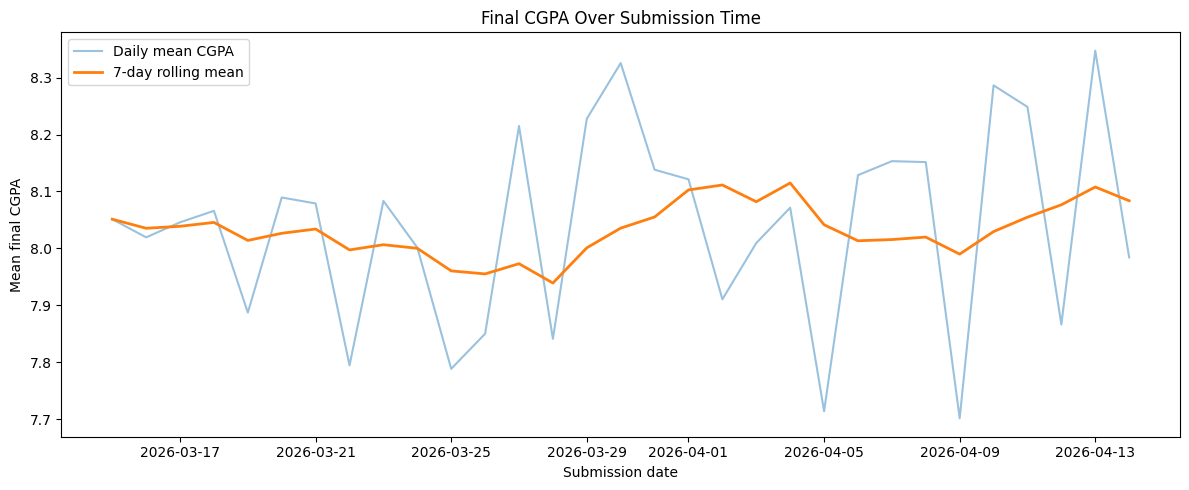

In [7]:
# Check whether rows are already sorted by timestamp
already_chronological = work_df["timestamp"].is_monotonic_increasing
print("Already chronological:", already_chronological)

# Sort once chronologically and keep this order for later parts
work_df = work_df.sort_values("timestamp").reset_index(drop=True)

# Plot daily CGPA averages and a seven-day rolling mean
daily_cgpa = work_df.set_index("timestamp")["final_cgpa"].resample("D").mean()
rolling_cgpa = daily_cgpa.rolling(window=7, min_periods=1).mean()

plt.figure(figsize=(12, 5))
plt.plot(daily_cgpa.index, daily_cgpa.values, alpha=0.45, label="Daily mean CGPA")
plt.plot(rolling_cgpa.index, rolling_cgpa.values, linewidth=2, label="7-day rolling mean")
plt.title("Final CGPA Over Submission Time")
plt.xlabel("Submission date")
plt.ylabel("Mean final CGPA")
plt.legend()
plt.tight_layout()
plt.show()

### Part A – Interpretation and risks


- Missing values can cause errors or inconsistent preprocessing if imputation is performed before splitting; imputation must be learned from training data only.
- Rare `cohort_code` categories can produce unstable category-specific estimates and unseen categories at test time.
- `performance_risk_level` is a potential target-leakage variable and must be excluded.
- Repeated survey answers can appear across train/test and inflate apparent performance; Part B.2 simulates this.
- Chronological changes in the rolling mean can indicate temporal drift, making a random split overly optimistic.

## Shared feature definitions for Parts B–D

In [8]:
# Define the exact eleven numeric/ordinal features listed in Part B
PART_B_FEATURES = [
    "study_hours", "sleep_hours", "attendance_rate", "study_consistency",
    "tasks_on_time", "assignments_on_time", "revision_frequency",
    "career_goal_clarity", "daily_productivity", "stress_level", "age",
    "submission_day"
]
TARGET = "final_cgpa"

# Exclude rows without a valid target, if any
model_df = work_df.dropna(subset=[TARGET]).copy()

# Ensure required columns exist
missing_required = [c for c in PART_B_FEATURES + [TARGET] if c not in model_df.columns]
if missing_required:
    raise ValueError(f"Required columns are missing: {missing_required}")

# Chronological 80/20 split reused throughout Parts B-D
split_index = int(len(model_df) * 0.80)
train_df = model_df.iloc[:split_index].copy()
test_df = model_df.iloc[split_index:].copy()

X_train = train_df[PART_B_FEATURES].copy()
y_train = train_df[TARGET].copy()
X_test = test_df[PART_B_FEATURES].copy()
y_test = test_df[TARGET].copy()

print("Training rows:", len(X_train), "Testing rows:", len(X_test))
print("Feature columns:", PART_B_FEATURES)

# Numeric-only preprocessing pipeline
numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

def make_numeric_tree():
    return Pipeline([
        ("preprocessor", numeric_preprocessor),
        ("model", DecisionTreeRegressor(random_state=RANDOM_STATE))
    ])

Training rows: 960 Testing rows: 240
Feature columns: ['study_hours', 'sleep_hours', 'attendance_rate', 'study_consistency', 'tasks_on_time', 'assignments_on_time', 'revision_frequency', 'career_goal_clarity', 'daily_productivity', 'stress_level', 'age', 'submission_day']


## Part B – Impact of Data Leakage and Evaluation Strategy

### B.1 Random split versus chronological split

In [9]:
# Build the complete numeric feature matrix
X_all = model_df[PART_B_FEATURES].copy()
y_all = model_df[TARGET].copy()

# Random 80/20 split
X_train_random, X_test_random, y_train_random, y_test_random = train_test_split(
    X_all, y_all, test_size=0.20, random_state=RANDOM_STATE
)

# Evaluate random split
random_model = make_numeric_tree()
random_model.fit(X_train_random, y_train_random)
random_train_rmse = rmse(y_train_random, random_model.predict(X_train_random))
random_test_rmse = rmse(y_test_random, random_model.predict(X_test_random))
random_baseline = DummyRegressor(strategy="mean").fit(X_train_random, y_train_random)
random_baseline_rmse = rmse(y_test_random, random_baseline.predict(X_test_random))

# Evaluate chronological split
chrono_model = make_numeric_tree()
chrono_model.fit(X_train, y_train)
chrono_train_rmse = rmse(y_train, chrono_model.predict(X_train))
chrono_test_rmse = rmse(y_test, chrono_model.predict(X_test))
chrono_baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)
chrono_baseline_rmse = rmse(y_test, chrono_baseline.predict(X_test))

B1_results = pd.DataFrame([
    {"Strategy": "Random split", "Training RMSE": random_train_rmse,
     "Testing RMSE": random_test_rmse, "Baseline Testing RMSE": random_baseline_rmse},
    {"Strategy": "Chronological split", "Training RMSE": chrono_train_rmse,
     "Testing RMSE": chrono_test_rmse, "Baseline Testing RMSE": chrono_baseline_rmse}
])
display(B1_results.round(4))

,Strategy,Training RMSE,Testing RMSE,Baseline Testing RMSE
0,Random split,0.0,1.6513,1.3385
1,Chronological split,0.0,2.0726,1.2362


**B.1 interpretation:** A random split mixes earlier and later submissions in both sets. A chronological split tests on later observations and better reflects prediction of future survey responses. A larger chronological test error can indicate temporal drift or a harder future period. 

### B.2 Duplicate leakage: split before removal versus removal before split

In [10]:
# Create a controlled duplicate dataset: duplicate 15% of rows
# Each copied response receives a new random timestamp within the survey period
base_for_duplicates = model_df.copy()
n_duplicate = int(round(0.15 * len(base_for_duplicates)))
duplicate_sample = base_for_duplicates.sample(n=n_duplicate, random_state=RANDOM_STATE).copy()

survey_start = base_for_duplicates["timestamp"].min()
survey_end = base_for_duplicates["timestamp"].max()
period_seconds = int((survey_end - survey_start).total_seconds())
rng = np.random.default_rng(RANDOM_STATE)
random_offsets = rng.integers(0, max(period_seconds, 1) + 1, size=n_duplicate)
duplicate_sample["timestamp"] = survey_start + pd.to_timedelta(random_offsets, unit="s")
duplicate_sample["submission_day"] = (
    duplicate_sample["timestamp"] - survey_start
).dt.total_seconds() / 86400

df_augmented = pd.concat([base_for_duplicates, duplicate_sample], ignore_index=True)
df_augmented = df_augmented.sort_values("timestamp").reset_index(drop=True)

# Duplicate identity ignores timestamp and submission_day, as requested
identity_columns = [c for c in df_augmented.columns if c not in ["timestamp", "submission_day"]]

# Strategy 1: chronological split first, then remove duplicates from training only
split_aug = int(len(df_augmented) * 0.80)
train_before = df_augmented.iloc[:split_aug].copy()
test_before = df_augmented.iloc[split_aug:].copy()
train_after = train_before.drop_duplicates(subset=identity_columns).copy()

# Strategy 2: remove duplicates first, then chronological split
df_clean = df_augmented.drop_duplicates(subset=identity_columns).copy()
df_clean = df_clean.sort_values("timestamp").reset_index(drop=True)
df_clean["submission_day"] = (
    df_clean["timestamp"] - survey_start
).dt.total_seconds() / 86400
split_clean = int(len(df_clean) * 0.80)
train_clean = df_clean.iloc[:split_clean].copy()
test_clean = df_clean.iloc[split_clean:].copy()

# Shared evaluator for the two duplicate strategies
def evaluate_duplicate_strategy(train_part, test_part):
    Xtr = train_part[PART_B_FEATURES]
    ytr = train_part[TARGET]
    Xte = test_part[PART_B_FEATURES]
    yte = test_part[TARGET]
    estimator = make_numeric_tree()
    estimator.fit(Xtr, ytr)
    return {
        "Training RMSE": rmse(ytr, estimator.predict(Xtr)),
        "Testing RMSE": rmse(yte, estimator.predict(Xte)),
        "Training Samples": len(train_part),
        "Testing Samples": len(test_part)
    }

B21_result = evaluate_duplicate_strategy(train_after, test_before)
B22_result = evaluate_duplicate_strategy(train_clean, test_clean)
B2_results = pd.DataFrame([
    {"Strategy": "Split first; remove train duplicates", **B21_result},
    {"Strategy": "Remove duplicates first; then split", **B22_result}
])
display(B2_results.round(4))
print("Artificial duplicate rows added:", n_duplicate)
print("Rows after global duplicate removal:", len(df_clean))

,Strategy,Training RMSE,Testing RMSE,Training Samples,Testing Samples
0,Split first; remove train duplicates,0.0,1.7769,983,276
1,Remove duplicates first; then split,0.0,1.8462,960,240


Artificial duplicate rows added: 180
Rows after global duplicate removal: 1200


**B.2.1 interpretation:** When splitting first, a duplicated response may occur in training and testing. The model can effectively see the same answers during training and evaluation, making test RMSE look better than true generalization. **B.2.2 interpretation:** Removing duplicates before splitting reduces this risk because copies cannot be distributed across the two sets.

### B.3 Preprocessing leakage with KNN

,Strategy,Training RMSE,Testing RMSE
0,Preprocessing before splitting (leakage),1.0855,1.1677
1,Preprocessing inside Pipeline,1.0793,1.1654


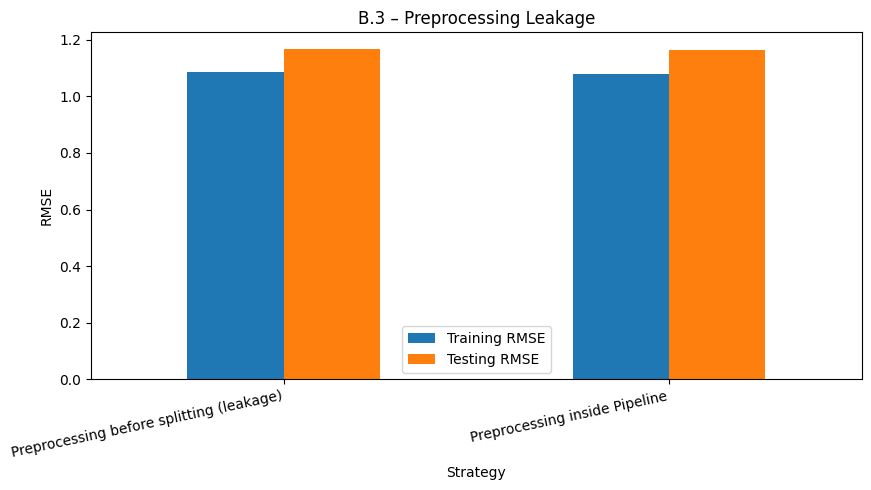

In [11]:
# Use the same chronological split as the rest of Part B
# Strategy 1 intentionally fits imputation and scaling on all rows before splitting
X_b3 = model_df[PART_B_FEATURES].copy()
y_b3 = model_df[TARGET].copy()

imputer_full = SimpleImputer(strategy="median")
X_imputed_full = imputer_full.fit_transform(X_b3)
scaler_full = StandardScaler()
X_scaled_full = scaler_full.fit_transform(X_imputed_full)
X_scaled_full = pd.DataFrame(X_scaled_full, columns=PART_B_FEATURES, index=X_b3.index)

X_train_full = X_scaled_full.iloc[:split_index]
X_test_full = X_scaled_full.iloc[split_index:]
y_train_b3 = y_b3.iloc[:split_index]
y_test_b3 = y_b3.iloc[split_index:]

knn_full = KNeighborsRegressor(n_neighbors=10)
knn_full.fit(X_train_full, y_train_b3)
train_rmse_full = rmse(y_train_b3, knn_full.predict(X_train_full))
test_rmse_full = rmse(y_test_b3, knn_full.predict(X_test_full))

# Strategy 2 learns imputation and scaling from training data only
knn_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("regressor", KNeighborsRegressor(n_neighbors=10))
])
knn_pipeline.fit(X_train, y_train)
train_rmse_pipeline = rmse(y_train, knn_pipeline.predict(X_train))
test_rmse_pipeline = rmse(y_test, knn_pipeline.predict(X_test))

B3_results = pd.DataFrame([
    {"Strategy": "Preprocessing before splitting (leakage)",
     "Training RMSE": train_rmse_full, "Testing RMSE": test_rmse_full},
    {"Strategy": "Preprocessing inside Pipeline",
     "Training RMSE": train_rmse_pipeline, "Testing RMSE": test_rmse_pipeline}
])
display(B3_results.round(4))
B3_results.set_index("Strategy").plot(kind="bar", figsize=(9, 5))
plt.title("B.3 – Preprocessing Leakage")
plt.ylabel("RMSE")
plt.xticks(rotation=12, ha="right")
plt.tight_layout()
plt.show()

**B.3 interpretation:** The first strategy leaks information because the median and scaling statistics are learned using the test observations. The Pipeline is leakage-safe because each transformer is fitted only on the training data. The numerical difference can be small, but the second procedure is the valid evaluation design.

## Part C – Understanding and Diagnosing Overfitting

### C.1 Effect of decision-tree complexity

,max_depth,Training RMSE,Testing RMSE,Generalization Gap
0,1,1.2231,1.1744,-0.0487
1,2,1.1833,1.1336,-0.0497
2,3,1.1456,1.1095,-0.0361
3,5,1.0711,1.9104,0.8392
4,10,0.7054,1.9982,1.2928
5,20,0.0000,2.0726,2.0726
6,None,0.0000,2.0726,2.0726


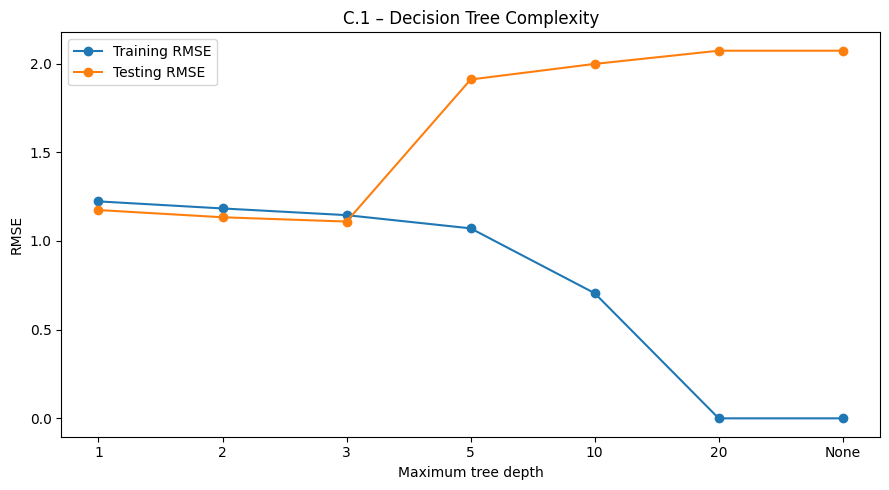

In [12]:
# Evaluate the requested tree depths on the fixed chronological split
depths = [1, 2, 3, 5, 10, 20, None]
C1_rows = []

for depth in depths:
    tree_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("tree", DecisionTreeRegressor(max_depth=depth, random_state=RANDOM_STATE))
    ])
    tree_pipeline.fit(X_train, y_train)
    train_error = rmse(y_train, tree_pipeline.predict(X_train))
    test_error = rmse(y_test, tree_pipeline.predict(X_test))
    C1_rows.append({
        "max_depth": "None" if depth is None else depth,
        "Training RMSE": train_error,
        "Testing RMSE": test_error,
        "Generalization Gap": test_error - train_error
    })

C1_results = pd.DataFrame(C1_rows)
display(C1_results.round(4))

# Plot training and testing errors
plot_depth = np.arange(len(depths))
plt.figure(figsize=(9, 5))
plt.plot(plot_depth, C1_results["Training RMSE"], marker="o", label="Training RMSE")
plt.plot(plot_depth, C1_results["Testing RMSE"], marker="o", label="Testing RMSE")
plt.xticks(plot_depth, [str(d) for d in depths])
plt.xlabel("Maximum tree depth")
plt.ylabel("RMSE")
plt.title("C.1 – Decision Tree Complexity")
plt.legend()
plt.tight_layout()
plt.show()

### C.2 Polynomial feature complexity

,Polynomial Degree,CV RMSE
0,1,1.1793
1,2,1.1790
2,3,1.1802
3,5,1.1850
4,9,1.1873
5,15,1.1894


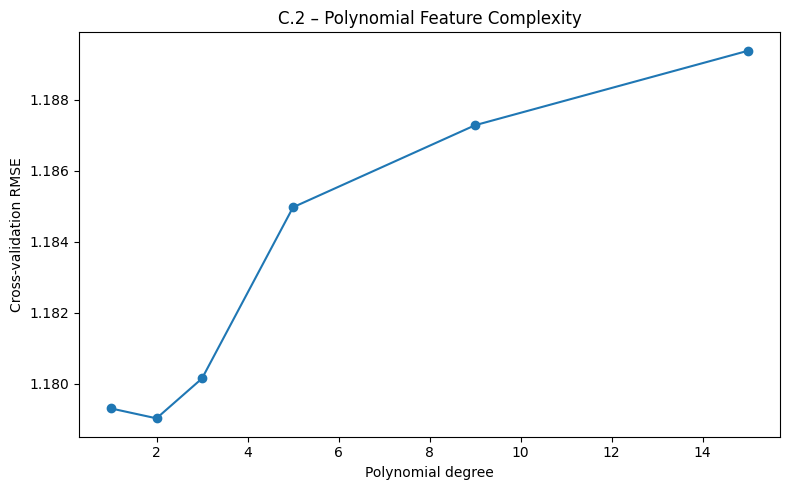

In [13]:
# Use effort_index only and training observations only
X_effort_train = train_df[["effort_index"]].copy()
y_effort_train = train_df[TARGET].copy()

# Remove rows with missing target only; imputation of the feature remains in the pipeline
# TimeSeriesSplit preserves chronological order inside the training set
tscv = TimeSeriesSplit(n_splits=5)
degrees = [1, 2, 3, 5, 9, 15]
C2_rows = []

for degree in degrees:
    polynomial_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("polynomial", PolynomialFeatures(degree=degree, include_bias=False)),
        ("scaler", StandardScaler()),
        ("regressor", LinearRegression())
    ])
    score = cv_rmse(polynomial_pipeline, X_effort_train, y_effort_train, tscv)
    C2_rows.append({"Polynomial Degree": degree, "CV RMSE": score})

C2_results = pd.DataFrame(C2_rows)
display(C2_results.round(4))
plt.figure(figsize=(8, 5))
plt.plot(C2_results["Polynomial Degree"], C2_results["CV RMSE"], marker="o")
plt.xlabel("Polynomial degree")
plt.ylabel("Cross-validation RMSE")
plt.title("C.2 – Polynomial Feature Complexity")
plt.tight_layout()
plt.show()

## Part D – Improving Model Generalization

### D.1 Handling high-cardinality cohort_code

In [14]:
# D.1 compares cohort encodings using training-only TimeSeriesSplit
X_d1 = train_df[PART_B_FEATURES].copy()
X_d1["cohort_code"] = train_df["cohort_code"].astype("string").fillna("Unknown")
y_d1 = y_train.copy()

num_cols_d1 = PART_B_FEATURES
cohort_col = ["cohort_code"]

# Rare-category grouping with OneHotEncoder
rare_preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols_d1),
    ("cohort", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(min_frequency=10, handle_unknown="infrequent_if_exist"))
    ]), cohort_col)
])
rare_model = Pipeline([
    ("preprocessor", rare_preprocessor),
    ("tree", DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE))
])
rare_score = cv_rmse(rare_model, X_d1, y_d1, tscv)

# Target encoding with internal cross-fitting to reduce target leakage
# TargetEncoder is available in recent scikit-learn versions
te_preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols_d1),
    ("cohort", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("target", TargetEncoder(target_type="continuous", smooth="auto", cv=5, shuffle=False))
    ]), cohort_col)
])
te_model = Pipeline([
    ("preprocessor", te_preprocessor),
    ("tree", DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE))
])
te_score = cv_rmse(te_model, X_d1, y_d1, tscv)

# Feature removal
X_d1_removed = train_df[PART_B_FEATURES].copy()
removed_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("tree", DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE))
])
removed_score = cv_rmse(removed_model, X_d1_removed, y_d1, tscv)

D1_results = pd.DataFrame([
    {"Approach": "Rare-category grouping + OneHot", "Validation RMSE": rare_score},
    {"Approach": "Cross-fitted Target Encoding", "Validation RMSE": te_score},
    {"Approach": "Remove cohort_code", "Validation RMSE": removed_score}
]).sort_values("Validation RMSE").reset_index(drop=True)
display(D1_results.round(4))
best_D1_approach = D1_results.iloc[0]["Approach"]
print("Best cohort treatment:", best_D1_approach)

,Approach,Validation RMSE
0,Rare-category grouping + OneHot,1.2993
1,Cross-fitted Target Encoding,1.3029
2,Remove cohort_code,1.3089


Best cohort treatment: Rare-category grouping + OneHot


### D.2 Feature selection: keep or remove submission_day

In [15]:
# Compare three model families with and without submission_day
base_features_d2 = [c for c in PART_B_FEATURES if c != "submission_day"]
feature_sets = {
    "With submission_day": PART_B_FEATURES,
    "Without submission_day": base_features_d2
}
D2_rows = []

for feature_label, feature_list in feature_sets.items():
    X_d2 = train_df[feature_list].copy()

    candidates = {
        "Linear Regression": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", LinearRegression())
        ]),
        "Decision Tree depth 5": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE))
        ]),
        "Gradient Boosting": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", GradientBoostingRegressor(
                n_estimators=60, learning_rate=0.05, max_depth=3,
                random_state=RANDOM_STATE
            ))
        ])
    }

    for model_name, estimator in candidates.items():
        score = cv_rmse(estimator, X_d2, y_train, tscv)
        D2_rows.append({
            "Model": model_name,
            "Feature Set": feature_label,
            "Validation RMSE": score
        })

D2_results = pd.DataFrame(D2_rows).sort_values("Validation RMSE").reset_index(drop=True)
display(D2_results.round(4))

# Decide based on the average validation RMSE across the three model families
D2_average = D2_results.groupby("Feature Set")["Validation RMSE"].mean().sort_values()
print("Average validation RMSE by feature set:")
display(D2_average.to_frame())
KEEP_SUBMISSION_DAY = (D2_average.index[0] == "With submission_day")
print("Keep submission_day:", KEEP_SUBMISSION_DAY)
FINAL_FEATURES = PART_B_FEATURES.copy() if KEEP_SUBMISSION_DAY else base_features_d2.copy()

,Model,Feature Set,Validation RMSE
0,Gradient Boosting,Without submission_day,1.1406
1,Linear Regression,Without submission_day,1.1460
2,Linear Regression,With submission_day,1.1539
3,Gradient Boosting,With submission_day,1.1675
4,Decision Tree depth 5,Without submission_day,1.2929
5,Decision Tree depth 5,With submission_day,1.3089


Average validation RMSE by feature set:


,Validation RMSE
Feature Set,
Without submission_day,1.193167
With submission_day,1.210092


Keep submission_day: False


**D.2 interpretation:**  Don't Keep `submission_day` becase without it the validation RMSE was improved .

### D.3 Applying regularization with degree-5 polynomial effort_index

In [16]:
# D.3 uses effort_index and target from the SAME chronological training rows
X_reg = train_df[["effort_index"]].copy().reset_index(drop=True)
y_reg = train_df[TARGET].copy().reset_index(drop=True)

# Verify sample alignment before cross-validation
assert len(X_reg) == len(y_reg), f"X_reg has {len(X_reg)} rows but y_reg has {len(y_reg)} rows"

alpha_values = [0.001, 0.01, 0.1, 1, 10, 100]
regularization_results = []

# Unregularized polynomial regression
linear_poly_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("polynomial", PolynomialFeatures(degree=5, include_bias=False)),
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])
linear_poly_rmse = cv_rmse(linear_poly_pipeline, X_reg, y_reg, tscv)
regularization_results.append({
    "Model": "Linear Regression", "Alpha": np.nan,
    "Validation RMSE": linear_poly_rmse
})

# Evaluate Ridge and Lasso for each alpha
for model_name, model_class in [("Ridge", Ridge), ("Lasso", Lasso)]:
    for alpha in alpha_values:
        estimator = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("polynomial", PolynomialFeatures(degree=5, include_bias=False)),
            ("scaler", StandardScaler()),
            ("regressor", model_class(alpha=alpha, max_iter=100000))
        ])
        score = cv_rmse(estimator, X_reg, y_reg, tscv)
        regularization_results.append({
            "Model": model_name, "Alpha": alpha,
            "Validation RMSE": score
        })

regularization_df = pd.DataFrame(regularization_results).sort_values("Validation RMSE").reset_index(drop=True)
display(regularization_df.round(4))

# Select the best Ridge/Lasso alpha for use in D.4 (D.4 uses unexpanded features)
penalized_results = regularization_df[regularization_df["Model"].isin(["Ridge", "Lasso"])]
best_penalized_row = penalized_results.iloc[0]
best_penalized_name = best_penalized_row["Model"]
best_penalized_alpha = float(best_penalized_row["Alpha"])
print("Best penalized model:", best_penalized_name)
print("Selected alpha:", best_penalized_alpha)

# Fit the selected polynomial model on all training rows to inspect coefficients
if best_penalized_name == "Ridge":
    selected_poly_model = clone(Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("polynomial", PolynomialFeatures(degree=5, include_bias=False)),
        ("scaler", StandardScaler()),
        ("regressor", Ridge(alpha=best_penalized_alpha))
    ]))
else:
    selected_poly_model = clone(Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("polynomial", PolynomialFeatures(degree=5, include_bias=False)),
        ("scaler", StandardScaler()),
        ("regressor", Lasso(alpha=best_penalized_alpha, max_iter=100000))
    ]))
selected_poly_model.fit(X_reg, y_reg)
selected_coefficients = selected_poly_model.named_steps["regressor"].coef_
print("Number of polynomial coefficients:", len(selected_coefficients))
print("Exactly-zero coefficients:", int(np.sum(selected_coefficients == 0)))

,Model,Alpha,Validation RMSE
0,Lasso,0.100,1.1786
1,Lasso,0.010,1.1789
2,Lasso,0.001,1.1796
3,Ridge,10.000,1.1798
4,Ridge,1.000,1.1800
5,Ridge,0.100,1.1805
6,Ridge,0.010,1.1817
7,Ridge,100.000,1.1825
8,Ridge,0.001,1.1825
9,Linear Regression,NaN,1.1850


Best penalized model: Lasso
Selected alpha: 0.1
Number of polynomial coefficients: 5
Exactly-zero coefficients: 4


### D.4 Final model comparison on the chronological test set

Final regularized model: Lasso alpha: 0.1
Selected tree depth: 2
Selected Gradient Boosting trees: 54


,Model,Training RMSE,Testing RMSE,Testing R2
0,Gradient Boosting (54 trees),1.0659,1.0680,0.2514
1,Linear Regression,1.1146,1.0824,0.2311
2,Lasso (alpha=0.1),1.1315,1.0977,0.2092
3,Decision Tree (depth=2),1.1833,1.1336,0.1567
4,Baseline (training mean),1.2685,1.2362,-0.0029


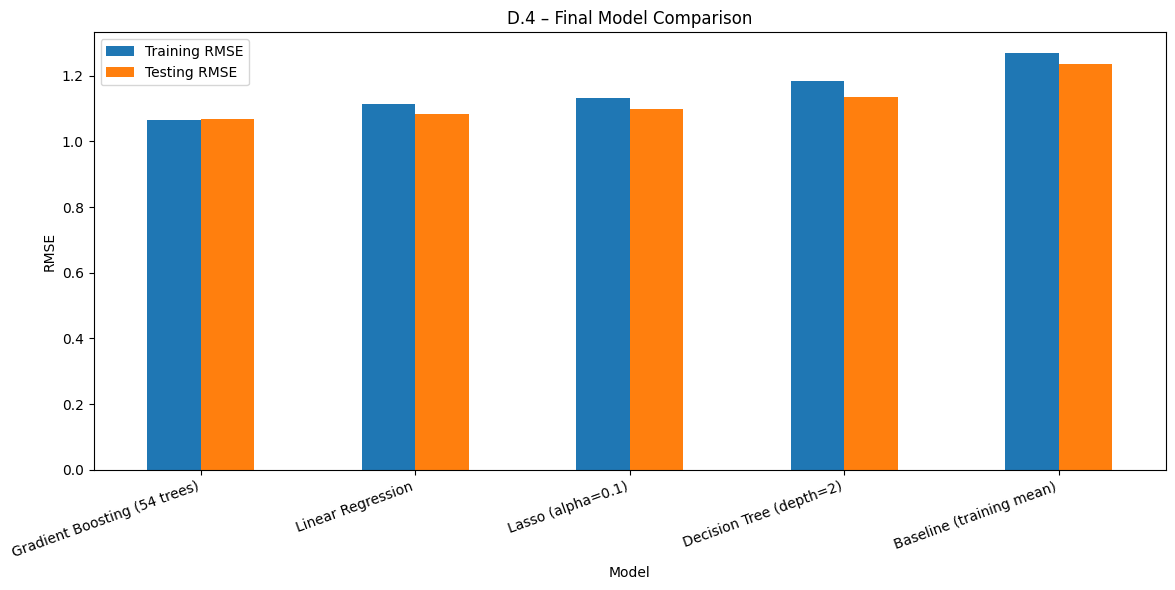

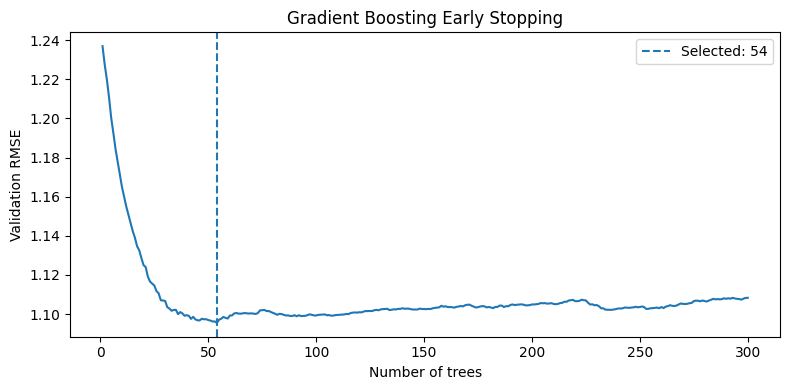

In [17]:
# D.4: all final models use the same selected Part B feature matrix
X_final_train = train_df[FINAL_FEATURES].copy()
X_final_test = test_df[FINAL_FEATURES].copy()
y_final_train = train_df[TARGET].copy()
y_final_test = test_df[TARGET].copy()

# Select Ridge/Lasso alpha on the final feature matrix using training-only CV
ridge_candidates = []
for alpha in alpha_values:
    ridge_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=alpha))
    ])
    ridge_candidates.append((alpha, cv_rmse(ridge_pipe, X_final_train, y_final_train, tscv)))
best_final_ridge_alpha = min(ridge_candidates, key=lambda item: item[1])[0]

lasso_candidates = []
for alpha in alpha_values:
    lasso_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", Lasso(alpha=alpha, max_iter=100000))
    ])
    lasso_candidates.append((alpha, cv_rmse(lasso_pipe, X_final_train, y_final_train, tscv)))
best_final_lasso_alpha = min(lasso_candidates, key=lambda item: item[1])[0]

if best_final_ridge_alpha == best_final_lasso_alpha:
    # Choose between Ridge and Lasso using their validation scores
    chosen_penalty = "Ridge" if min(ridge_candidates, key=lambda x: x[1])[1] <= min(lasso_candidates, key=lambda x: x[1])[1] else "Lasso"
else:
    chosen_penalty = "Ridge" if min(ridge_candidates, key=lambda x: x[1])[1] <= min(lasso_candidates, key=lambda x: x[1])[1] else "Lasso"
chosen_alpha = best_final_ridge_alpha if chosen_penalty == "Ridge" else best_final_lasso_alpha
print("Final regularized model:", chosen_penalty, "alpha:", chosen_alpha)

# Select decision-tree depth using TimeSeriesSplit on training data only
tree_depth_scores = []
for depth in [1, 2, 3, 5, 10, 20, None]:
    tree_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeRegressor(max_depth=depth, random_state=RANDOM_STATE))
    ])
    tree_depth_scores.append((depth, cv_rmse(tree_pipe, X_final_train, y_final_train, tscv)))
best_tree_depth = min(tree_depth_scores, key=lambda item: item[1])[0]
print("Selected tree depth:", best_tree_depth)

# Baseline model
baseline_final = DummyRegressor(strategy="mean").fit(X_final_train, y_final_train)

# Linear regression
linear_final = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", LinearRegression())
]).fit(X_final_train, y_final_train)

# Selected Ridge or Lasso
regularized_class = Ridge if chosen_penalty == "Ridge" else Lasso
regularized_final = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", regularized_class(alpha=chosen_alpha, max_iter=100000))
]).fit(X_final_train, y_final_train)

# Selected decision tree
tree_final = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DecisionTreeRegressor(max_depth=best_tree_depth, random_state=RANDOM_STATE))
]).fit(X_final_train, y_final_train)

# Gradient Boosting: reserve the last 15% of training chronologically for early stopping
inner_split = int(len(X_final_train) * 0.85)
X_gb_fit = X_final_train.iloc[:inner_split]
y_gb_fit = y_final_train.iloc[:inner_split]
X_gb_valid = X_final_train.iloc[inner_split:]
y_gb_valid = y_final_train.iloc[inner_split:]

gb_preprocessor = SimpleImputer(strategy="median")
X_gb_fit_imp = gb_preprocessor.fit_transform(X_gb_fit)
X_gb_valid_imp = gb_preprocessor.transform(X_gb_valid)

gb_search = GradientBoostingRegressor(
    n_estimators=300, learning_rate=0.05, max_depth=3,
    random_state=RANDOM_STATE
)
gb_search.fit(X_gb_fit_imp, y_gb_fit)

staged_validation_errors = []
for n_trees, predictions in enumerate(gb_search.staged_predict(X_gb_valid_imp), start=1):
    staged_validation_errors.append((n_trees, rmse(y_gb_valid, predictions)))
best_n_estimators, best_gb_validation_rmse = min(staged_validation_errors, key=lambda x: x[1])
print("Selected Gradient Boosting trees:", best_n_estimators)

# Refit the selected number of trees on the full training set
# Refit the selected number of trees on the full training set
gb_final = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", GradientBoostingRegressor(
        n_estimators=best_n_estimators, learning_rate=0.05, max_depth=3,
        random_state=RANDOM_STATE
    ))
]).fit(X_final_train, y_final_train)

# Evaluate all models on the same training and untouched final test partition
final_models = {
    "Baseline (training mean)": baseline_final,
    "Linear Regression": linear_final,
    f"{chosen_penalty} (alpha={chosen_alpha})": regularized_final,
    f"Decision Tree (depth={best_tree_depth})": tree_final,
    f"Gradient Boosting ({best_n_estimators} trees)": gb_final
}

D4_rows = []
for model_name, estimator in final_models.items():
    train_predictions = estimator.predict(X_final_train)
    test_predictions = estimator.predict(X_final_test)
    D4_rows.append({
        "Model": model_name,
        "Training RMSE": rmse(y_final_train, train_predictions),
        "Testing RMSE": rmse(y_final_test, test_predictions),
        "Testing R2": r2_score(y_final_test, test_predictions)
    })

D4_results = pd.DataFrame(D4_rows).sort_values("Testing RMSE").reset_index(drop=True)
display(D4_results.round(4))

# Plot train and test RMSE for final models
D4_results.set_index("Model")[["Training RMSE", "Testing RMSE"]].plot(
    kind="bar", figsize=(12, 6)
)
plt.title("D.4 – Final Model Comparison")
plt.ylabel("RMSE")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

# Plot the staged Gradient Boosting validation RMSE
plt.figure(figsize=(8, 4))
plt.plot([x[0] for x in staged_validation_errors], [x[1] for x in staged_validation_errors])
plt.axvline(best_n_estimators, linestyle="--", label=f"Selected: {best_n_estimators}")
plt.xlabel("Number of trees")
plt.ylabel("Validation RMSE")
plt.title("Gradient Boosting Early Stopping")
plt.legend()
plt.tight_layout()
plt.show()

## Final checks

In [18]:
# Confirm the key data dimensions and selected settings
print("Original dataset shape:", raw_df.shape)
print("Model dataset shape:", model_df.shape)
print("Chronological train/test sizes:", len(train_df), len(test_df))
print("Final features:", FINAL_FEATURES)
print("Selected cohort treatment:", best_D1_approach)
print("Keep submission_day:", KEEP_SUBMISSION_DAY)
print("Selected final regularization:", chosen_penalty, chosen_alpha)
print("Selected tree depth:", best_tree_depth)
print("Selected boosting estimators:", best_n_estimators)

Original dataset shape: (1200, 36)
Model dataset shape: (1200, 40)
Chronological train/test sizes: 960 240
Final features: ['study_hours', 'sleep_hours', 'attendance_rate', 'study_consistency', 'tasks_on_time', 'assignments_on_time', 'revision_frequency', 'career_goal_clarity', 'daily_productivity', 'stress_level', 'age']
Selected cohort treatment: Rare-category grouping + OneHot
Keep submission_day: False
Selected final regularization: Lasso 0.1
Selected tree depth: 2
Selected boosting estimators: 54


## Final Discussion

**1. Which model achieves the best generalization?**

Gradient Boosting achieves the best generalization among the tested models. It has the lowest Testing RMSE of **1.0680** and the highest Testing R² of **0.2514**. The model uses 54 estimators, selected through chronological validation. This indicates that Gradient Boosting performs better than the other models on unseen test data.

**2. Which model shows the largest generalization gap?**

In the final D.4 comparison, Gradient Boosting has the largest numerical generalization gap, calculated as Testing RMSE minus Training RMSE:

- Gradient Boosting: 1.0680 - 1.0659 = **0.0021**
- Linear Regression: 1.0824 - 1.1146 = **-0.0322**
- Lasso: 1.0977 - 1.1315 = **-0.0338**
- Decision Tree: 1.1336 - 1.1833 = **-0.0497**

Therefore, Gradient Boosting has the largest numerical gap, but the gap is very small. None of the final models shows a large positive generalization gap. In contrast, Part C.1 clearly demonstrates overfitting in deeper decision trees. For example, the tree with depth 20 has a Training RMSE of 0.0000 and a Testing RMSE of 2.0726, resulting in a generalization gap of 2.0726.

**3. Which techniques were most effective in preventing overfitting and improving generalization?**

Several techniques helped improve model reliability:

- **Duplicate removal before splitting:** In B.2, removing duplicates before splitting produced a Testing RMSE of 1.8462, compared with 1.7769 when splitting first and removing duplicates only from training. Although the first approach did not produce a lower RMSE in this experiment, removing duplicates before splitting is the safer approach because it reduces the risk of identical responses appearing in both training and testing sets.
- **Pipeline-based preprocessing:** In B.3, preprocessing inside a Pipeline achieved a Testing RMSE of 1.1654, compared with 1.1677 when preprocessing was performed before splitting. The difference is small, but the Pipeline approach is methodologically correct because imputation and scaling are fitted using training data only.
- **Limiting decision tree depth:** Part C.1 showed that deeper trees overfit the training data. The tree with depth 2 achieved a Testing RMSE of 1.1336, while deeper trees produced much larger generalization gaps.
- **Feature selection:** In D.2, removing submission_day improved the average validation RMSE from 1.2101 to 1.1932. Therefore, submission_day was excluded from the final feature set.
- **Regularization:** In D.3, Lasso with alpha = 0.1 achieved the best validation RMSE of 1.1786 among the tested regularized models. It also reduced 4 out of 5 polynomial coefficients to exactly zero, helping simplify the model.
- **Model selection using chronological validation:** TimeSeriesSplit helped select features and hyperparameters without using the final test set.

Overall, the most useful techniques were controlling model complexity, using leakage-safe preprocessing, selecting relevant features, and applying regularization.

**4. Why should model selection be based on validation performance rather than training performance?**

Training performance measures how well a model fits data that it has already seen. A complex model may achieve very low training error but perform poorly on unseen observations because it has memorized the training data.

Validation performance provides a more realistic estimate of generalization. In this practical session, TimeSeriesSplit was used on the training data to compare models and select hyperparameters. Therefore, validation performance provides a more reliable basis for model selection than training performance alone.

**5. Why must the final test set remain untouched during model selection?**

The final test set must remain untouched because it is intended to provide an independent evaluation of the selected model.

If the test set is repeatedly used to choose features, models, or hyperparameters, information from the test set indirectly influences the modelling decisions. This creates test-set leakage and makes the final performance estimate overly optimistic.

In this practical session, validation data was used for model selection, while the chronological test set was reserved for the final comparison in D.4.

**6. What does a modest best R² value indicate about the dataset?**

The best model, Gradient Boosting, achieved a Testing R² of **0.2514**. This means that the model explains approximately 25.14% of the variation in final CGPA on the test set.

Although Gradient Boosting performed better than the other tested models, the result indicates that the available survey features have limited predictive power. Student performance may also depend on important factors that are not included in the dataset, such as previous academic results, course difficulty, teaching quality, and personal circumstances.

Furthermore, many variables are self-reported or represented by categories, which may introduce measurement noise.

Therefore, a modest R² is a realistic indication of the limitations of the available features. A very high score should be examined carefully because it could result from data leakage, duplicate contamination, or the inclusion of information directly related to the target variable.